In [1]:
import pandas as pd

df = pd.read_csv(r"/Users/britneyspiercegnanadhas/Downloads/raw_dataset.csv", sep=";")

print(df.head())
print(df.info())

  ball-bearing  humidity vibration
0       93.744    73.999        18
1        93.74    73.999    18.001
2       93.736    73.998    18.002
3       93.732    73.998    18.003
4       93.729    73.998    18.004
<class 'pandas.DataFrame'>
RangeIndex: 112001 entries, 0 to 112000
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   ball-bearing  112001 non-null  str    
 1   humidity      112001 non-null  float64
 2   vibration     112001 non-null  str    
dtypes: float64(1), str(2)
memory usage: 2.6 MB
None


In [2]:
print(df.isnull().sum())

ball-bearing    0
humidity        0
vibration       0
dtype: int64


In [3]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 3462


In [4]:
df = df.drop_duplicates()

In [5]:
print("Duplicate rows after cleaning:", df.duplicated().sum())

Duplicate rows after cleaning: 0


In [6]:
print(df.dtypes)

ball-bearing        str
humidity        float64
vibration           str
dtype: object


In [7]:
df["ball-bearing"] = pd.to_numeric(df["ball-bearing"], errors="coerce")
df["humidity"] = pd.to_numeric(df["humidity"], errors="coerce")
df["vibration"] = pd.to_numeric(df["vibration"], errors="coerce")

In [8]:
print(df.dtypes)

ball-bearing    float64
humidity        float64
vibration       float64
dtype: object


In [9]:
print("\nMissing values after conversion:")
print(df.isnull().sum())


Missing values after conversion:
ball-bearing     535
humidity           0
vibration       5241
dtype: int64


In [10]:
df = df.dropna()

In [11]:
print("\nFinal shape:", df.shape)
print("Final duplicates:", df.duplicated().sum())


Final shape: (102777, 3)
Final duplicates: 0


In [12]:
print("\nDataset summary:")
print(df.describe())


Dataset summary:
        ball-bearing       humidity      vibration
count  102777.000000  102777.000000  102777.000000
mean       45.714130      74.205155      28.912828
std        19.083365       0.693104      24.294005
min        16.933000      72.399000       2.000000
25%        27.475000      73.898000       8.000000
50%        42.769000      74.191000      21.529000
75%        63.781000      74.701000      39.675000
max        93.744000      75.400000      99.995000


In [13]:
print("\nMissing values conversion:")
print(df.isnull().sum())


Missing values conversion:
ball-bearing    0
humidity        0
vibration       0
dtype: int64


In [14]:
df.to_csv("cleaned_dataset.csv", index=False)

print("\nCleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [15]:
print(df.columns.tolist())

['ball-bearing', 'humidity', 'vibration']


In [16]:
print(df.head())

   ball-bearing  humidity  vibration
0        93.744    73.999     18.000
1        93.740    73.999     18.001
2        93.736    73.998     18.002
3        93.732    73.998     18.003
4        93.729    73.998     18.004


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("Visualization", exist_ok=True)

df = pd.read_csv("cleaned_dataset.csv")

print(df.columns.tolist())
print(df.head())

['ball-bearing', 'humidity', 'vibration']
   ball-bearing  humidity  vibration
0        93.744    73.999     18.000
1        93.740    73.999     18.001
2        93.736    73.998     18.002
3        93.732    73.998     18.003
4        93.729    73.998     18.004


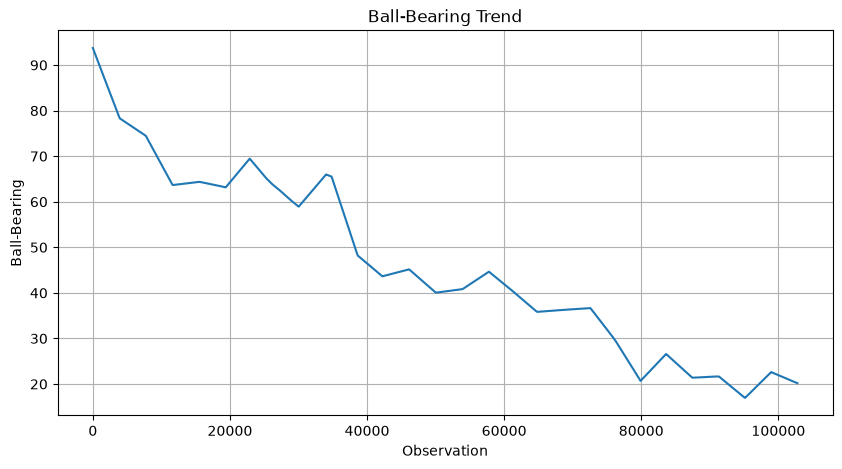

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(df["ball-bearing"])

plt.title("Ball-Bearing Trend")
plt.xlabel("Observation")
plt.ylabel("Ball-Bearing")
plt.grid(True)

plt.savefig(os.path.join("Visualization", "ball_bearing_trend.png"), dpi=300, bbox_inches="tight")

plt.show()

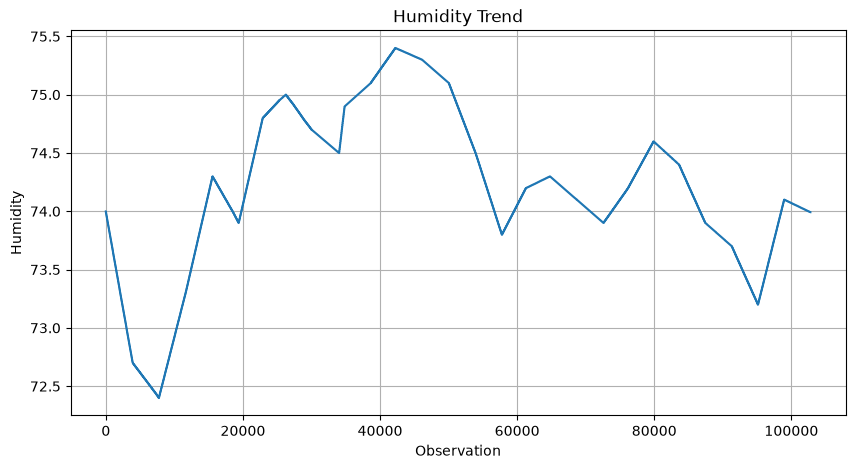

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(df["humidity"])

plt.title("Humidity Trend")
plt.xlabel("Observation")
plt.ylabel("Humidity")
plt.grid(True)

plt.savefig(os.path.join("Visualization", "humidity_trend.png"), dpi=300, bbox_inches="tight")

plt.show()

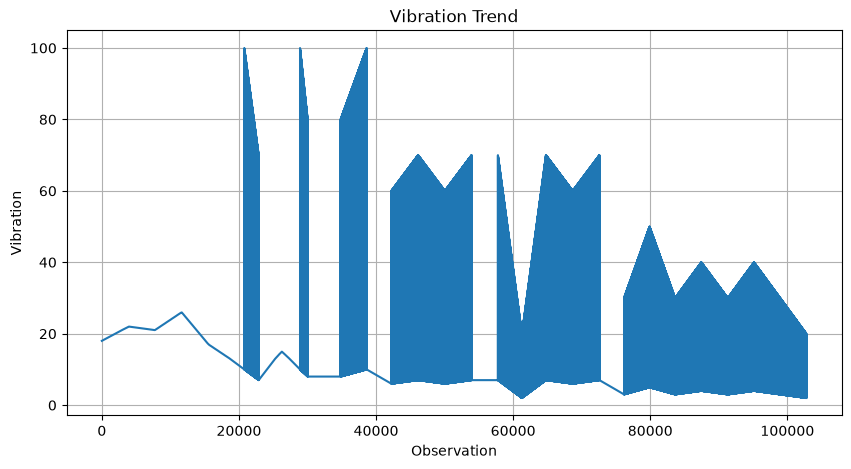

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(df["vibration"])

plt.title("Vibration Trend")
plt.xlabel("Observation")
plt.ylabel("Vibration")
plt.grid(True)

plt.savefig(os.path.join("Visualization", "vibration_trend.png"), dpi=300, bbox_inches="tight")

plt.show()

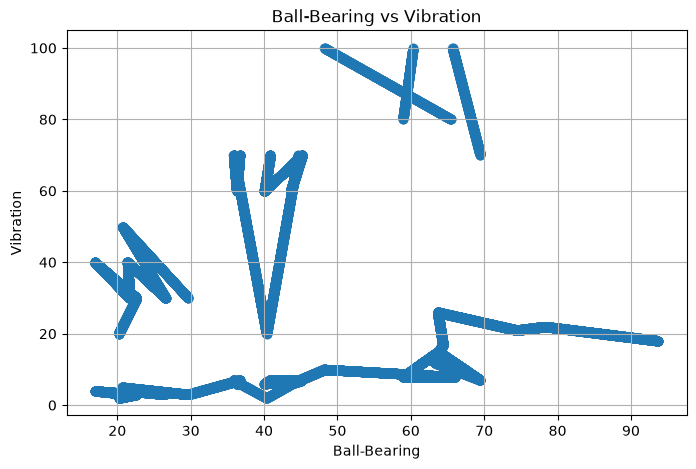

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["ball-bearing"],
    df["vibration"],
    alpha=0.3
)

plt.title("Ball-Bearing vs Vibration")
plt.xlabel("Ball-Bearing")
plt.ylabel("Vibration")
plt.grid(True)

plt.savefig(os.path.join("Visualization", "ball_bearing_vs_vibration.png"), dpi=300, bbox_inches="tight")

plt.show()

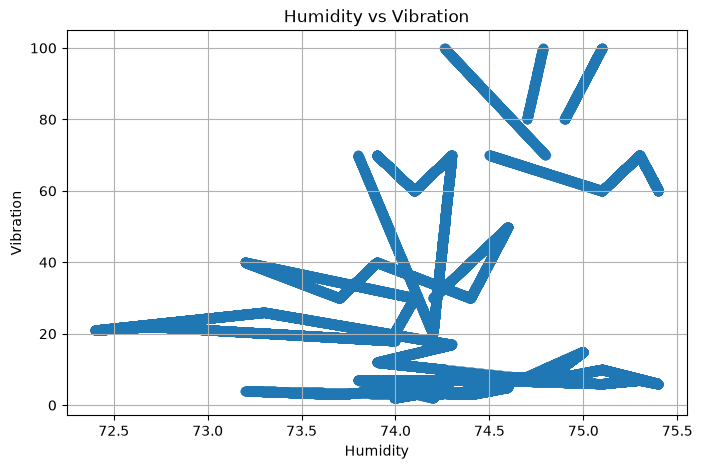

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["humidity"],
    df["vibration"],
    alpha=0.3
)

plt.title("Humidity vs Vibration")
plt.xlabel("Humidity")
plt.ylabel("Vibration")
plt.grid(True)

plt.savefig(os.path.join("Visualization", "humidity_vs_vibration.png"), dpi=300, bbox_inches="tight")

plt.show()

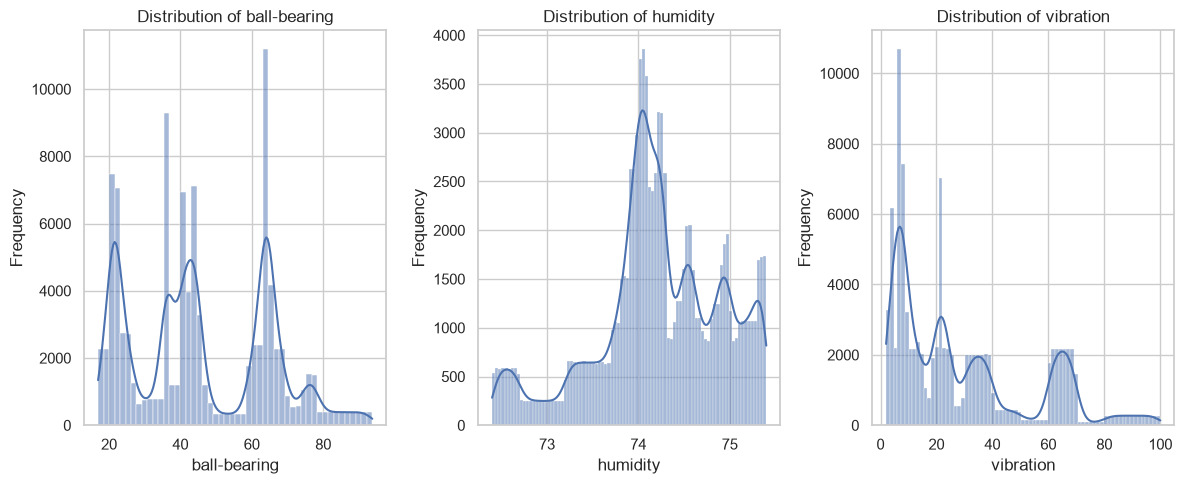

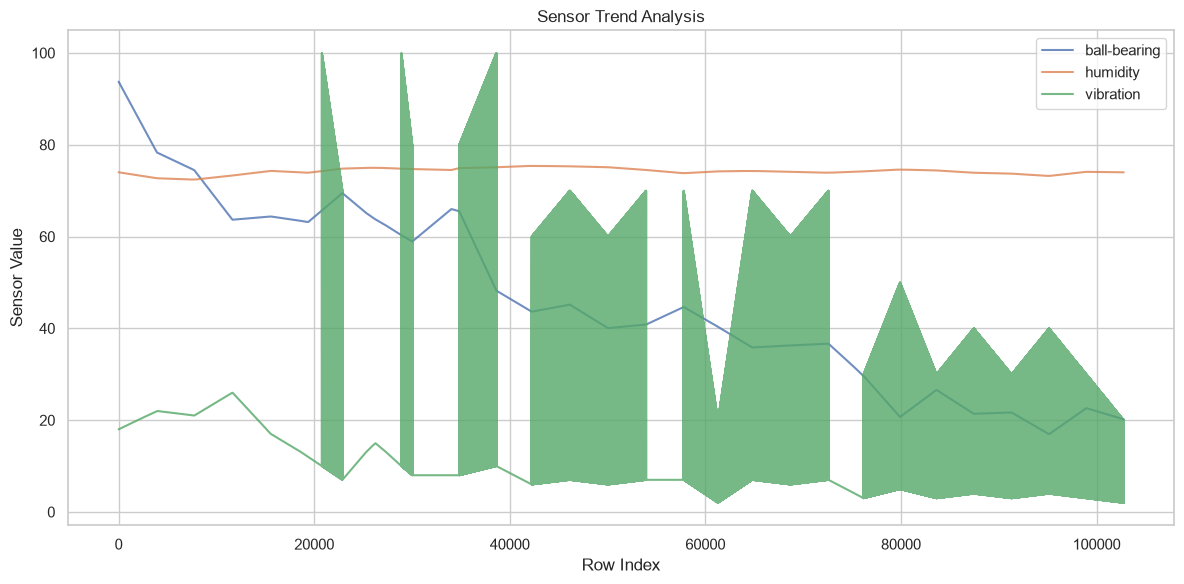

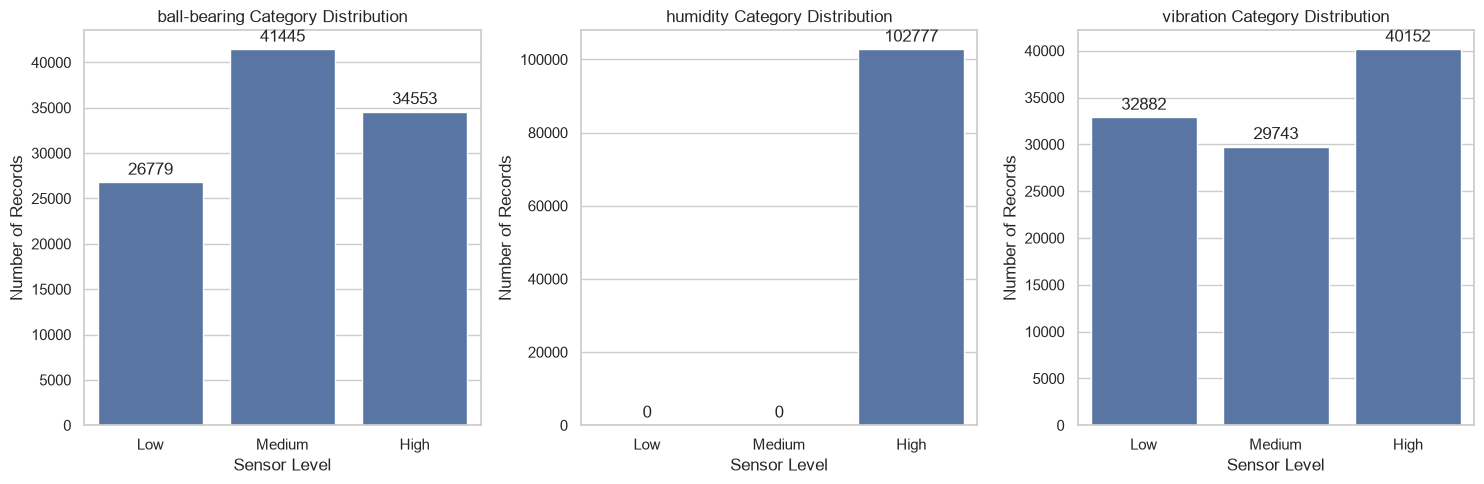

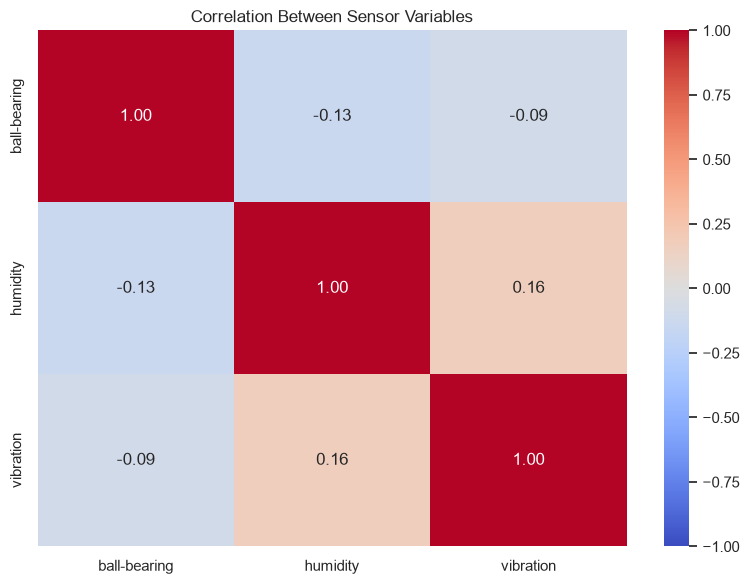

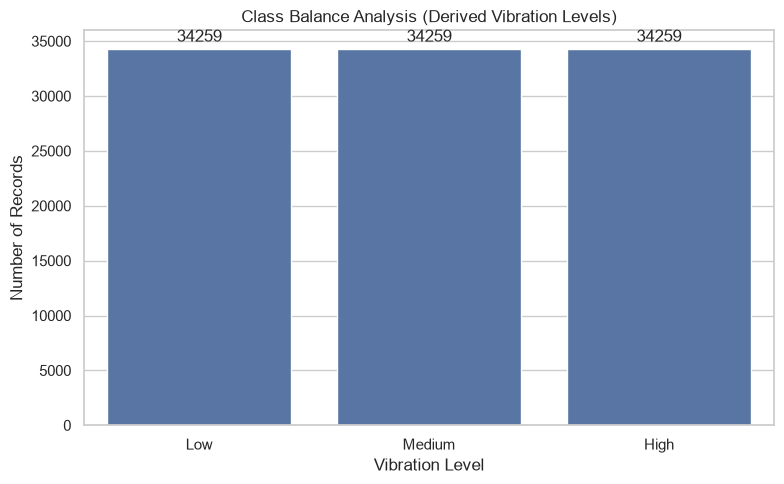

Dataset shape after cleaning: (102777, 3)

Missing values:
ball-bearing    0
humidity        0
vibration       0
dtype: int64

Correlation matrix:
              ball-bearing  humidity  vibration
ball-bearing      1.000000 -0.134749  -0.089993
humidity         -0.134749  1.000000   0.164449
vibration        -0.089993  0.164449   1.000000

All visualizations saved in the 'Visualization' folder.


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load the cleaned dataset
df = pd.read_csv("cleaned_dataset.csv")
df.columns = df.columns.str.strip()

# Convert sensor columns to numeric values
columns = ["ball-bearing", "humidity", "vibration"]
for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove duplicate rows and rows with missing sensor values
df = df.drop_duplicates()
df = df.dropna(subset=columns)

# Create the output folder automatically if it does not exist
OUTPUT_DIR = "Visualization"
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")

# 1. DISTRIBUTION ANALYSIS
plt.figure(figsize=(12, 5))
for i, col in enumerate(columns, 1):
    plt.subplot(1, 3, i)
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "distribution_analysis.png"),
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 2. TREND ANALYSIS
plt.figure(figsize=(12, 6))
for col in columns:
    plt.plot(df.index, df[col], label=col, alpha=0.8)
plt.title("Sensor Trend Analysis")
plt.xlabel("Row Index")
plt.ylabel("Sensor Value")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "trend_analysis.png"),
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 3. CATEGORY ANALYSIS
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
categories = {
    "ball-bearing": [0, 30, 60, 100],
    "humidity": [0, 50, 70, 100],
    "vibration": [0, 10, 30, 100]
}
labels = ["Low", "Medium", "High"]

for ax, col in zip(axes, columns):
    ranges = categories[col]
    grouped = pd.cut(
        df[col],
        bins=ranges,
        labels=labels,
        include_lowest=True
    )
    counts = grouped.value_counts().reindex(labels, fill_value=0)
    sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax)
    ax.set_title(f"{col} Category Distribution")
    ax.set_xlabel("Sensor Level")
    ax.set_ylabel("Number of Records")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "category_analysis.png"),
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 4. CORRELATION ANALYSIS
plt.figure(figsize=(8, 6))
correlation = df[columns].corr()
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1)
plt.title("Correlation Between Sensor Variables")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "correlation_analysis.png"),
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 5. CLASS BALANCE ANALYSIS
# The dataset has no confirmed target/class column, so create Low/Medium/High
# vibration groups from the data distribution. This is a derived class balance,
# not a machine-failure label.
vibration_classes = pd.qcut(
    df["vibration"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)
class_counts = vibration_classes.value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values)
plt.title("Class Balance Analysis (Derived Vibration Levels)")
plt.xlabel("Vibration Level")
plt.ylabel("Number of Records")
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt="%.0f", padding=3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "class_balance_analysis.png"),
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Display final dataset information
print("Dataset shape after cleaning:", df.shape)
print("\nMissing values:")
print(df[columns].isnull().sum())
print("\nCorrelation matrix:")
print(correlation)
print(f"\nAll visualizations saved in the '{OUTPUT_DIR}' folder.")
